# Tutorial 1: Introduction to strax and abstrax, and data handling

**Who this tutorial is for:**
You are new to strax, but you know Python, numpy and matplotlib, and the basics of a dual-phase liquid xenon TPC. You don't need to know anything about strax or any other strax-based framework.

**strax and abstrax in a nutshell:**
strax provides the infrastructure to transform raw data from your light sensors into reconstructed pairs of S1 and S2 signals, while abstrax provides the concrete building blocks for this transformation: from raw signals to S1 and S2 peaks, and eventually to events of paired S1 and S2 signals. When adapting this to your own detector, you would eventually build your own "abstrax", while leaving strax mostly untouched.

Generally, strax organizes data as a stream of time intervals, such as waveforms, sorted by time. This concept makes it possible to work with data acquisition systems whose light sensors trigger independently, as well as with event-level triggered systems. strax does not require your data stream to be continuous: you can have gaps in the data, e.g., between two event triggers, or between two simulated events that were placed on an arbitrary time axis. Thus, strax can be used with nearly any system that has to process peak-like signals.

**What you will learn:**
1. Explain what strax does, and what abstrax adds on top of it.
2. Describe the strax data model: a time-ordered stream of intervals, cut into chunks and transformed by plugins.
3. Tell a *data type* from a *data kind*.
4. Read how strax data is organised on disk.
5. Set up a context and its storage, and keep read-only data safe.
6. Load data efficiently: arrays vs DataFrames, loading only part of the data, and iterating chunk by chunk.
7. Understand lineage: why changing a setting reprocesses some data types but not others, and how to find out why strax can't find your data.
8. Register and select runs without a run database.

**What comes in later tutorials:**

* Tutorial 2, *Data of LXe TPCs*: here you learn how to use strax/abstrax to transform raw light sensor waveforms into reconstructed peaks, and eventually into events (pairs of S1 and S2 signals).
* Tutorial 3, *Custom plugins*: plugins are the backbone of these transformations. They divide the processing chain into small, self-contained and exchangeable steps. In tutorial 3 you will learn how plugins are structured and how you can develop one yourself.
* Tutorial 4, *Cuts and cut acceptances*: here you will learn how to define data quality cuts and apply them to your data.
* A separate tutorial (planned) on bringing your own data: how to convert the output of your DAQ or simulation into strax `raw_records`.

## The data used in this tutorial

abstrax ships example data in `abstrax/test_data`. The tutorial uses two runs based on simulated data. In strax, runs are identified by a run ID (a string); here we use 6-digit IDs such as `012882`. The tutorial provides:

* `SHORT_RUN`, a short run that starts from raw light sensor data, called `raw_records`. We use it to show how strax processes data.
* `LONG_RUN`, a longer run of a uniformly distributed calibration source (Kr83m-like simulation). It is stored only as high-level data, i.e. information about the S1 and S2 peaks, and about S1 and S2 signals paired into events. We use it to load and analyse data.

`test_data` is shared, **read-only** storage. We never write into it. Everything strax produces in this tutorial goes into `OUTPUT_FOLDER`, which you can delete at any time.

> **Note:** the simulated runs are not in `test_data` yet. Until they are, both names point to run `012882`, a small run with only about 40 peaks, so some numbers and plots in this tutorial will look sparse.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import strax
import abstrax

# Read-only example data shipped with abstrax (path relative to the tutorials folder)
TEST_DATA = Path('../test_data').resolve()

# Writable folder for everything we produce. Safe to delete.
OUTPUT_FOLDER = Path('./strax_data').resolve()

# Placeholders until the simulated runs are added to test_data
# short run, raw_records available
# This data is some seconds of true XENONnT data 
# and is shipped with straxen to perfrom 
# unit tests
SHORT_RUN = '012882'  

# This data was simulated with ember the
# strax-based open source waveform simulation 
# tool. The data is only XENONnT-like and 
# was generated based on some dummy maps. 
# Also the PMT laypout is different than 
# XENONnTs true PMT layout.
LONG_RUN = '000001'   

print('Test data:    ', TEST_DATA, '| exists:', TEST_DATA.exists())
print('Output folder:', OUTPUT_FOLDER)

Test data:     /mnt/d/XLZD/mymodules/abstrax/test_data | exists: True
Output folder: /mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data


# 1. strax, abstrax and the strax way of thinking

Before we touch any data, we would like to give you a short overview of strax and abstrax. We will dive deeper into the individual concepts later in the tutorials.

## 1.1 What strax is

[strax](https://github.com/AxFoundation/strax) ("streaming analysis for xenon experiments") is a Python framework for processing time-ordered detector data. Despite the name, it knows nothing about any particular detector, and it can work with any detector that records time-sorted signals, e.g. from any type of light sensor. strax provides the machinery everything else is built on. When you develop your own application, this infrastructure is already there for you, and you rarely have to change anything in it.

* **Plugins.** Plugins are the building blocks of your data transformation. Each plugin represents one processing step that transforms data of one type into another. For example, a plugin takes your raw light sensor waveforms as input and transforms them into S1 and S2 peaks. A plugin declares which data it needs (`depends_on`), which data it makes (`provides`), the format of its output (`dtype`), the settings used for the transformation, and the version of the plugin code. strax itself does not provide any plugins; plugins are developed freely by the user. abstrax provides a basic set of plugins you can start from to build your own processing framework. A more complex example of a set of plugins is [straxen](https://github.com/XENONnT/straxen), the processing framework of the XENONnT collaboration.
* **The context.** This is the object you work with. It stores which plugins you have registered to transform your data, how they are configured and where your data is stored. The context also assists you in processing your data. When you request some data, the context checks whether the data is already stored, or which plugins have to run to make the data for you on the fly (assuming that a lower-level data type is available).
* **Lineage and caching.** To organize the data, and to process it for you on the fly if it is not stored, strax labels stored data with lineage hashes. A hash encodes the lineage of the data: the plugins, including their versions, that were used to make it, and the settings of these plugins. strax loads stored data when the hash matches, and recomputes it when it doesn't.
* **Configuration.** Settings are declared through URL-like strings that encode how a setting has to be loaded. A `URLConfig` can be anything from a single constant value read from a file or database to a complex map that is interpolated for you on the fly while processing data.
* **Storage.** Storage frontends tell strax where to look for data. This can be anything from local directories to databases and remote storage. The storage backends define how the data is written, compressed and read.
* **Processing.** The processor organizes how data is processed through the chain of plugins. In general, data is grouped into *chunks*, memory-friendly pieces of data that stream through the plugins either in series or in parallel. This ensures that large runs can be processed without having to fit into memory at once. As the user, you decide whether a plugin can be processed fully in parallel or must be processed in series.
* **Fast helpers.** strax also contains a set of numba-compiled functions for common waveform-processing steps, such as `strax.find_hits` or `strax.find_peaks`. These functions are optimized for speed, and you can use them in your own plugins.

The figure below shows how these pieces fit together. You only talk to the context; it connects storage, settings, plugins and the processor for you. We will learn more about the individual concepts during the tutorials.

<center><img src="images/straxen_overview.png" width="700"/></center>

## 1.2 What abstrax is

strax alone doesn't process anything; it needs plugins that serve as building blocks to transform your data from raw waveforms into something meaningful. abstrax provides these for a **generic, abstract dual-phase TPC**. While its plugins are based on [straxen](https://github.com/XENONnT/straxen), the open-source processing software of the XENONnT collaboration, abstrax doesn't model any specific experiment. abstrax is meant to be a convenient starting point to familiarize yourself with the concepts of strax and to get started with your own project. It consists of:

* **Plugins** to process raw data into events (`raw_records → records → peaks → events`).
* **A dummy detector description**, `abstrax/config/detector.yaml`. This is the single place for detector parameters such as the number of PMTs, the top/bottom array split, the TPC length, the drift velocity, g1 and g2. Plugins read these through `URLConfig` strings like `detector://n_tpc_pmts`, so you can describe a different detector without changing any plugin code. TODO: This may change with the simulated data.
* **A context builder**, `abstrax.contexts.abstrax_context()`, which returns a strax context with all abstrax plugins registered and local storage set up. It needs no database and no network.

## 1.3 The strax paradigm: a stream of time intervals, not a list of events

Many analysis frameworks are **event-based**. A trigger defines an event window, and every event is a self-contained record, for example one row of parameters in a large table. strax works a bit differently here: it sorts data by time.

* **The basic unit is a time interval.** Every object has a start `time` and an end: a PMT pulse, a hit, a peak, an event, a chunk, even a whole run. The end is stored either directly as `endtime`, or as `length` samples of width `dt`, so that `endtime = time + length * dt`.
* **Times are integers in nanoseconds since the unix epoch** (`int64`). There are no floats, so there is no rounding error, even at ns precision over runs lasting many hours.
* **Within each data type, intervals are always sorted by `time`.** strax relies on this everywhere.
* **A run is one time-ordered stream of data (gaps are allowed).** Events are not how the data is organised. They are just another data type: a plugin builds them from peaks, by opening a time window around each large S2 that could contain its S1.

Thinking in streams has practical advantages. Low-level data doesn't depend on a trigger decision, which gives you more flexibility. The same tools work at every data level, and you can redefine what an event is.

What this means for your own data: if your DAQ or simulation writes data event by event, you can still use strax. You only have to make sure that everything uses a common, sorted time axis. For example, the test data used in this tutorial comes from event-based simulations. Their time axis was chosen such that the simulated events are well separated in time, e.g., by placing them several drift times apart. A triggered detector system can also use strax, as long as the data within each trigger window is sorted by time, which is usually the case.

**In practice**, you will mostly work with event-level data such as `event_basics`: one row per event, with quantities like the S1 and S2 areas and the drift time. This looks much like the per-event tables you may know from event-based frameworks. The difference is how you get there: strax builds this table from the stream of data, and can rebuild it with different settings.

Every strax data type starts with the time fields. There are two variants:

In [2]:
# Variant 1: explicit start and end time (e.g. events)
strax.time_fields

[(('Start time since unix epoch [ns]', 'time'), numpy.int64),
 (('Exclusive end time since unix epoch [ns]', 'endtime'), numpy.int64)]

This variant is usually used for data that only contains summary quantities, like the area or height of a peak. For waveforms, the following variant is used instead:

In [3]:
# Variant 2: start time plus length * dt (data with waveforms, e.g. records and peaks)
strax.interval_dtype

[(('Start time since unix epoch [ns]', 'time'), numpy.int64),
 (('Length of the interval in samples', 'length'), numpy.int32),
 (('Width of one sample [ns]', 'dt'), numpy.int16),
 (('Channel/PMT number', 'channel'), numpy.int16)]

Here, the data contains information about when a time interval starts, how many samples it lasts and how long each sample is. Usually, these intervals are also associated with a channel number, for example of a light sensor.

`strax.endtime()` computes the end time for both variants. Let's build three intervals by hand:

In [4]:
intervals = np.zeros(3, dtype=strax.interval_dtype)
intervals['time'] = [1_000, 2_000, 5_000]  # ns
intervals['length'] = [10, 20, 5]          # samples
intervals['dt'] = 10                       # ns per sample

strax.endtime(intervals)

array([1100, 2200, 5050])

## 1.4 Plugins, data types and data kinds

A **plugin** turns one or more data types into new ones. For example, the `PeakBasics` plugin takes `peaks` and computes basic properties such as area, width and rise time, which it stores as `peak_basics`.

A **data type** is the name of one plugin output, for example `peak_basics`. Each data type has its own `dtype` and is stored separately on disk. A plugin can provide more than one data type: abstrax's `PulseProcessing` plugin, for example, provides both `records` and `pulse_counts`.

A **data kind** groups data types that describe the *same objects*, with one row per object and identical time intervals. `peaks`, `peak_basics` and `peak_positions` are all of kind `peaks`: row *i* of each describes the same peak. Because of this, strax can load data types of the same kind together and merge them column by column. We'll use this a lot in section 3.

Plugins stack like building blocks to form your custom processing chain. This logical division makes it easy for you to build up your processing chain, and to replace a step with something new without touching the rest of your code. Each plugin is a self-contained processing step.

<center><img src="images/DataTypes.png" width="600"/></center>

Usually, this also means that the lowest data types in your processing chain are the most memory-heavy, and the more you refine your data, the lighter it becomes.

Let's ask abstrax which plugins it has. To do that we need a context. We'll look at contexts in detail in section 2; for now, we only use it to look at the plugin graph.

In [5]:
st = abstrax.contexts.abstrax_context(output_folder=OUTPUT_FOLDER)

`st.tree` maps each data type to the data types it depends on, and `st.get_data_kinds()` tells us the data kind of each data type. Together they describe the whole processing chain:

In [6]:
data_types_per_kind, kind_of = st.get_data_kinds()

rows = []
for data_type, depends_on in st.tree.items():
    plugin = st.get_single_plugin(SHORT_RUN, data_type)
    rows.append({
        'data type': data_type,
        'made by plugin': type(plugin).__name__,
        'depends on': ', '.join(dict.fromkeys(depends_on)) or '(nothing: raw data)',
        'data kind': kind_of[data_type],
    })

pd.DataFrame(rows)

,data type,made by plugin,depends on,data kind
0,raw_records,DAQReader,(nothing: raw data),raw_records
1,records,PulseProcessing,raw_records,records
2,pulse_counts,PulseProcessing,raw_records,pulse_counts
3,peaklets,Peaklets,records,peaklets
4,lone_hits,Peaklets,records,lone_hits
5,peaklet_classification,PeakletClassification,peaklets,peaklets
6,merged_s2s,MergedS2s,"peaklets, peaklet_classification, lone_hits",merged_s2s
7,peaks,Peaks,"peaklets, peaklet_classification, merged_s2s",peaks
8,peak_basics,PeakBasics,peaks,peaks
9,peak_positions,PeakPositions,peaks,peaks


A few things to notice:

* `raw_records` depends on nothing. It is the entry point of the chain, provided by the raw data interface plugin.
* `PulseProcessing` and `Peaklets` each provide two data types.
* `peaklet_classification` has the same kind as `peaklets`: it adds one classification (S1, S2 or unknown) per peaklet.
* The data types of kind `peaks` (`peaks`, `peak_basics`, `peak_positions`) and of kind `events` (`events`, `event_basics`, `corrected_areas`, ...) can each be loaded together in one call.
* Some data types are a kind of their own, for example `lone_hits`, which are hits that didn't end up in any peak.

Grouped by data kind:

In [7]:
data_types_per_kind

{'raw_records': ['raw_records'],
 'records': ['records'],
 'pulse_counts': ['pulse_counts'],
 'peaklets': ['peaklets', 'peaklet_classification'],
 'lone_hits': ['lone_hits'],
 'merged_s2s': ['merged_s2s'],
 'peaks': ['peaks', 'peak_basics', 'peak_positions'],
 'events': ['events',
  'event_basics',
  'corrected_areas',
  'energy_estimates',
  'event_info']}

You can also ask for everything a data type needs, directly or indirectly. This is what strax works out when you request data that isn't stored yet:

In [8]:
needed = st.get_dependencies('event_basics')  # a set; list it in processing order
[data_type for data_type in st.tree if data_type in needed]

['raw_records',
 'records',
 'peaklets',
 'lone_hits',
 'peaklet_classification',
 'merged_s2s',
 'peaks',
 'peak_basics',
 'peak_positions',
 'events']

Each plugin carries its own declaration. Here is what `PeakBasics` says about itself. Tutorial 3 shows how to write such a plugin:

In [9]:
plugin = st.get_single_plugin(SHORT_RUN, 'peak_basics')

print('depends_on:', plugin.depends_on)
print('provides:  ', plugin.provides)
print('data_kind: ', plugin.data_kind)
print('version:   ', plugin.__version__)
print('fields:    ', plugin.dtype_for('peak_basics').names)

depends_on: ('peaks',)
provides:   ('peak_basics',)
data_kind:  peaks
version:    0.0.1
fields:     ('time', 'endtime', 'center_time', 'area', 'n_hits', 'n_channels', 'top_n_channels', 'max_pmt', 'max_pmt_area', 'n_saturated_channels', 'range_50p_area', 'range_90p_area', 'area_fraction_top', 'length', 'dt', 'median_time', 'rise_time', 'tight_coincidence', 'type', 'max_diff', 'min_diff', 'first_channel', 'last_channel')


## 1.5 Runs and chunks

A **run** is a period of data taking, or of simulated data, with a start time, an end time and a run ID. The run is the unit strax processes and stores data in: you always ask for a data type *of a run*, for example `peak_basics` of run `012882`. Information about the run itself, such as its start and end time, the run mode or tags, is stored as *run metadata*. We come back to this in section 5.

A run can last hours and hold far more data than fits into memory. strax therefore cuts the data of each data type into **chunks**:

* A chunk has a `start` and an `end` time and contains all intervals of that data type which fall within `[start, end)`.
* The chunks of a data type cover the full time range of the run, without gaps and without overlaps.
* Plugins process data chunk by chunk. Chunks move from one plugin to the next as if on a conveyor belt, and several chunks can be in flight at the same time.

<center><img src="images/StraxChunks.png" width="800"/></center>

Within a chunk, the data is a **numpy structured array**: a table with one row per interval and a fixed set of typed columns (the `dtype`). For waveform data, one column holds the samples. The figure below shows a run cut into chunks, and the content of one chunk of raw data: each row is a *record*, a fixed-length piece of a PMT pulse. A pulse longer than one record is split into several records, numbered by `record_i`, while `pulse_length` keeps the length of the whole pulse.

<center><img src="images/Chunking.png" width="700"/></center>

Chunk sizes also change along the processing chain. When strax saves a data type, it combines consecutive small chunks into larger ones, up to a target size of 200 MB by default (set by the plugin attribute `chunk_target_size_mb`). Low-level data such as `records` is therefore stored in many chunks, while high-level data such as `event_basics` often fits a whole run into a few chunks, or even a single one.

Each data kind has its own chunk boundaries, so a chunk of `peaks` and a chunk of `events` usually don't start and end at the same time. When strax combines data of different kinds, it takes care of this for you.

We'll see what chunks look like on disk in section 2, and how to work with them directly in section 3.

## 1.6 Summary: the most important terms

| Term | Meaning | More in |
|---|---|---|
| Run | A period of data taking or simulation, with a start time, an end time and a run ID. The unit strax processes and stores data in. | 1.5, 5 |
| Time interval | The basic strax object: a start `time` in ns since the unix epoch, plus an end (`endtime`, or `length` × `dt`). | 1.3 |
| Chunk | A piece of one data type of a run, covering `[start, end)`. The chunks of a data type cover the run without gaps or overlaps. | 1.5, 2, 3 |
| Data type | One named plugin output, for example `peak_basics`, with its own `dtype`. Each data type is stored separately. | 1.4, 3 |
| Data kind | A group of data types that describe the same objects row by row, for example `peaks`. Data types of one kind can be loaded together. | 1.4, 3 |
| Plugin | One processing step: it takes data types (`depends_on`) and makes new ones (`provides`). | 1.4, tutorial 3 |
| Context | The object you work with. It holds the registered plugins, their configuration and the storage locations. | 2 |
| Lineage | The plugins, versions and settings that produced a data type. strax stores it as a hash in the name of the data folder. | 2, 4 |

# 2. The context, data lineage and storage

## 2.1 Software versions

strax can process data on the fly, depending on the settings and plugin versions you want to use. It is therefore useful, especially when developing, to first check which software versions you are using:

In [10]:
abstrax.print_versions()

,module,version,path,git
0,python,3.12.16,/home/dwenz/miniconda3/envs/xlzd/bin/python,None
1,strax,2.2.3,/mnt/d/XLZD/mymodules/strax/strax,branch:move_url_configs_to_strax | b7c90d9
2,abstrax,0.0.1,/mnt/d/XLZD/mymodules/abstrax/abstrax,branch:main | 4ef707a


The output of a strax processing chain depends on the versions of strax, abstrax and their plugins. Note these versions in your analysis notes, and always include this table when you report a bug or ask for help. If a package is installed from a git repository, the table also shows the branch and commit. With its `modules` argument, `print_versions` can also list any other package.

## 2.2 The context

As described in section 1.1, the context is the object you work with. It defines how your data is processed, and it holds three things:

1. the **registered plugins**, which define which data types can be made and how,
2. the **configuration** of these plugins,
3. the **storage**: where strax looks for data, and where it saves new data.

Importantly, you can change any of these three parts even after initializing the context. This makes it quick and easy to develop new plugins or to test new settings.

`abstrax.contexts.abstrax_context()` builds such a context for you in this tutorial. It creates a `strax.Context`, registers the raw data interface plugin and all abstrax processing plugins, and sets up local storage. It needs no database and no network connection. Below you can see the code of the abstrax context:

In [11]:
abstrax.contexts.abstrax_context??

Signature:
abstrax.contexts.abstrax_context(
    output_folder: 'str | Path' = './strax_data',
    **context_kwargs,
) -> 'strax.Context'
Source:   
def abstrax_context(
    output_folder: str | Path = "./strax_data",
    **context_kwargs,
) -> strax.Context:
    """Build a strax.Context with the abstrax plugins registered.

    Parameters
    ----------
    output_folder
        Directory for cached strax data. Created if it does not exist.
    **context_kwargs
        Forwarded to ``strax.Context``.
    """
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)

    st = strax.Context(
        storage=[
            strax.DataDirectory(str(output_folder), readonly=False, provide_run_metadata=True)
        ],
        register=[],
        **context_kwargs,
    )

    # Register the interface plugin that provides the raw data, e.g. from a DAQ
    # or from simulations:
    st.register(_raw_records.DAQReader)

    # Register plugins required to proces

For the tutorial, the only important argument is `output_folder`, the directory in which strax saves the data it makes. For tutorials and quick tests, use a folder whose content you can delete at any time without thinking about it. For a real analysis, use a dedicated folder per analysis, so you can keep track of which data belongs to it. If you don't pass anything, strax uses `./strax_data` relative to your notebook, and such folders quickly get messy.

Let's initialize the context for our tutorial again:

In [12]:
st = abstrax.contexts.abstrax_context(output_folder=OUTPUT_FOLDER)

Most of the time, plugins use their default settings, and we will learn later how to adjust them. Usually, the context only overwrites a small number of settings, for example PMT gains, which may change over time.

All settings that differ from their default values are listed in the context config:

In [13]:
st.config

{'gain_model': 'numpy:///mnt/d/XLZD/mymodules/abstrax/abstrax/resources/fake_to_pe_494_0.005.npy'}

## 2.3 Storage

`st.storage` is the list of places where strax looks for data, called **storage frontends**. A storage frontend can be anything from a local directory to a database. In this tutorial we only work with the `DataDirectory` storage frontend, a plain directory on a local disk. We can list all storage frontends of our context via:

In [14]:
st.storage

[strax.storage.files.DataDirectory (path: /mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data)]

Let us now check whether the tutorial data shipped with the repository is accessible. For this we can use `st.is_stored`, which takes two arguments: the ID of the run and the data type we want to load, in this case `raw_records`:

In [15]:
st.is_stored(SHORT_RUN, 'raw_records')

False

To be able to load the test data, we first have to add its directory as a second storage frontend. Directories that contain data shared with many people, or raw data, should always be marked as **read-only**, so that we cannot accidentally mess them up:

In [16]:
st.storage.append(strax.DataDirectory(str(TEST_DATA), readonly=True))
st.storage

[strax.storage.files.DataDirectory (path: /mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data),
 strax.storage.files.DataDirectory (readonly: True, path: /mnt/d/XLZD/mymodules/abstrax/test_data)]

In [17]:
st.is_stored(SHORT_RUN, 'raw_records')

True

Now strax finds our data.

Two rules decide how strax uses the storage list:

* **Looking for data:** strax checks the frontends from the fastest storage type to the slowest, for example local directories before remote storage. Frontends of the same type are checked in list order. The first frontend that has the data wins.
* **Saving data:** strax saves new data into **every writable** frontend. Read-only frontends are only ever read from.

`st.writable_storage()` shows where new data will go:

In [18]:
st.writable_storage()

[strax.storage.files.DataDirectory (path: /mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data)]

**Always add shared data as read-only.** If a shared directory is writable, strax saves everything you make into it. Your test outputs then mix with the shared data, and every setting you try adds another copy of the data. Mark shared data with `readonly=True`, and keep a single writable `output_folder` that belongs to you.

To better understand how data is organized in strax, we have to look at the data files themselves. A `DataDirectory` contains one folder per run and data type. Let us now look at the folder containing our tutorial data:

In [19]:
sorted(os.listdir(TEST_DATA))

['000001-event_basics-i4eieszxl6',
 '000001-peak_basics-t7ibxh2r4t',
 '012882-raw_records-flwge4rc3n',
 'dummy_binary_files']

Here we find a list of folders. Each folder name has three parts, separated by `-`:

<center><img src="images/lineage.png" width="800"/></center>

1. The **run ID**.
2. The **data type**.
3. The **lineage hash**, a short fingerprint of the data's *lineage* that encodes the plugins, their versions and all their settings, down to the raw data. If any of these change, the hash changes too.

Because of the hash, the same data type of the same run can be stored several times, once for each set of settings, and strax always knows which copy matches your current context. The context computes the expected folder name with `st.key_for`. We'll come back to this in section 4.

In [20]:
st.key_for(SHORT_RUN, 'raw_records')

012882-raw_records-flwge4rc3n

Inside the `raw_records` folder we find a list of files:

In [21]:
raw_folder = TEST_DATA / str(st.key_for(SHORT_RUN, 'raw_records'))

for file in sorted(raw_folder.iterdir()):
    print(f'{file.stat().st_size / 1e3:10.1f} kB   {file.name}')

    4575.7 kB   raw_records-flwge4rc3n-000000
       1.5 kB   raw_records-flwge4rc3n-metadata.json


A data folder contains two kinds of files:

* **Chunk files**, named `<data_type>-<lineage_hash>-<chunk number>`. Each holds one chunk of data (see section 1.5) as compressed binary data.
* **One metadata file**, `<data_type>-<lineage_hash>-metadata.json`, which describes the data and every chunk.

The metadata file is plain JSON, so we can open it directly:

In [22]:
import json

meta_file = os.path.join(raw_folder, 'raw_records-flwge4rc3n-metadata.json')
with open(meta_file) as f:
    metadata = json.load(f)

metadata

{'chunk_target_size_mb': 200,
 'chunks': [{'chunk_i': 0,
   'end': 4876677420,
   'filename': 'raw_records-flwge4rc3n-000000',
   'filesize': 4575713,
   'first_endtime': 125000600,
   'first_time': 124999590,
   'last_endtime': 4876676730,
   'last_time': 4876676080,
   'n': 34445,
   'nbytes': 8404580,
   'run_id': '012882',
   'start': 124900000,
   'subruns': None}],
 'compressor': 'blosc',
 'data_kind': 'raw_records',
 'data_type': 'raw_records',
 'dtype': "[(('Start time since unix epoch [ns]', 'time'), '<i8'), (('Length of the interval in samples', 'length'), '<i4'), (('Width of one sample [ns]', 'dt'), '<i2'), (('Channel/PMT number', 'channel'), '<i2'), (('Length of pulse to which the record belongs (without zero-padding)', 'pulse_length'), '<i4'), (('Fragment number in the pulse', 'record_i'), '<i2'), (('Baseline determined by the digitizer (if this is supported)', 'baseline'), '<i2'), (('Waveform data in raw ADC counts', 'data'), '<i2', (110,))]",
 'end': 4876677420,
 'lineag

Luckily, strax already has a built-in method to load this metadata file, without you having to know anything about the storage frontend it is stored in:

In [23]:
st.get_metadata(SHORT_RUN, 'raw_records')

{'chunk_target_size_mb': 200,
 'chunks': [{'chunk_i': 0,
   'end': 4876677420,
   'filename': 'raw_records-flwge4rc3n-000000',
   'filesize': 4575713,
   'first_endtime': 125000600,
   'first_time': 124999590,
   'last_endtime': 4876676730,
   'last_time': 4876676080,
   'n': 34445,
   'nbytes': 8404580,
   'run_id': '012882',
   'start': 124900000,
   'subruns': None}],
 'compressor': 'blosc',
 'data_kind': 'raw_records',
 'data_type': 'raw_records',
 'dtype': "[(('Start time since unix epoch [ns]', 'time'), '<i8'), (('Length of the interval in samples', 'length'), '<i4'), (('Width of one sample [ns]', 'dt'), '<i2'), (('Channel/PMT number', 'channel'), '<i2'), (('Length of pulse to which the record belongs (without zero-padding)', 'pulse_length'), '<i4'), (('Fragment number in the pulse', 'record_i'), '<i2'), (('Baseline determined by the digitizer (if this is supported)', 'baseline'), '<i2'), (('Waveform data in raw ADC counts', 'data'), '<i2', (110,))]",
 'end': 4876677420,
 'lineag

The information in this file can be roughly divided into the following categories:

| Key | Meaning |
|---|---|
| `run_id`, `data_type`, `data_kind` | What this data is |
| `dtype` | The fields of the data, with their types and descriptions |
| `lineage`, `lineage_hash` | Which plugins, versions and settings made the data, and its hash |
| `compressor` | How the chunk files are compressed |
| `start`, `end` | Time range covered by the data, in ns since the unix epoch |
| `chunk_target_size_mb` | Target size when chunks were combined on saving (section 1.5) |
| `chunks` | One entry per chunk file |
| `strax_version`, `writing_started`, `writing_ended` | When and with which strax version the data was written |

Each entry in `chunks` describes one compressed binary chunk file containing our data: its number (`chunk_i`), the time range it covers (`start`, `end`), the number of rows (`n`), its size in memory (`nbytes`) and its compressed size on disk (`filesize`):

In [24]:
chunks = pd.DataFrame(metadata['chunks'])
print(f"Compression factor: {chunks['nbytes'].sum() / chunks['filesize'].sum():.1f}")
chunks[['chunk_i', 'start', 'end', 'n', 'nbytes', 'filesize', 'filename']]

Compression factor: 1.8


,chunk_i,start,end,n,nbytes,filesize,filename
0,0,124900000,4876677420,34445,8404580,4575713,raw_records-flwge4rc3n-000000


# 3. Loading data

Enough theory, let's load some data! In this section we mostly use `LONG_RUN`, which contains high-level data such as `peak_basics` and `event_basics`. To show how much memory low-level data needs, we also use the `raw_records` of `SHORT_RUN`.

> **Note:** until the simulated runs are available, `LONG_RUN` points to the short test run, which only contains `raw_records`. strax therefore has to process the data the first time you load it, which takes about half a minute. Section 4 explains what happens there.

In [25]:
st = abstrax.contexts.abstrax_context(output_folder=OUTPUT_FOLDER)
st.storage.append(strax.DataDirectory(str(TEST_DATA), readonly=True))

## 3.1 Arrays and DataFrames

To load data, you always tell the context two things: the **run ID** and the **data type**. There are two main ways to load data. `st.get_array` returns a numpy structured array:

In [26]:
peak_basics = st.get_array(LONG_RUN, 'peak_basics')
peak_basics

Loading peak_basics: |          | 0.00 % [00:00<?]

array([(           30,           620,            30,   33.343567,   70,  68,  25, 384, 1.5324997e+00, 0,    25.696884,    54.20907, 0.3424465 ,  59,  10,    86.34719 ,    26.52452 , 53, 1,  70, 0, 294, 436),
       (      1403330,       1435170,       1417729, 5857.9136  , 3123, 457, 227, 222, 9.6028699e+02, 0,  8329.946   , 20182.129  , 0.7924202 , 199, 160, 14539.994   ,  8299.221   , 23, 2, 560, 0, 150, 338),
       (     20000030,      20000910,      20000155,   83.57422 ,   65,  63,  18, 273, 3.2094719e+00, 0,    60.153503,   336.45493, 0.26010922,  88,  10,    91.72753 ,    37.824013, 49, 1, 150, 0, 356, 357),
       ...,
       (1999962102360, 1999962142890, 1999962125098, 4941.317   , 3099, 453, 218,  20, 7.6085626e+02, 0, 11622.564   , 27469.9    , 0.78832006, 193, 210, 23893.203   , 12805.066   , 20, 2, 570, 0,  37, 332),
       (1999980000030, 1999980000730, 1999980000166,   75.56756 ,   63,  61,  30, 117, 3.1558008e+00, 0,    76.50216 ,   324.18875, 0.52132446,  70,  10,   

Each row describes one peak. The names of the columns, called *fields*, are stored in the `dtype`:

In [27]:
peak_basics.dtype.names

('time',
 'endtime',
 'center_time',
 'area',
 'n_hits',
 'n_channels',
 'top_n_channels',
 'max_pmt',
 'max_pmt_area',
 'n_saturated_channels',
 'range_50p_area',
 'range_90p_area',
 'area_fraction_top',
 'length',
 'dt',
 'median_time',
 'rise_time',
 'tight_coincidence',
 'type',
 'max_diff',
 'min_diff',
 'first_channel',
 'last_channel')

If you need more information about the individual columns, you can run the following:

In [28]:
st.data_info('peak_basics')

,Field name,Data type,Comment
0,time,int64,Start time since unix epoch [ns]
1,endtime,int64,Exclusive end time since unix epoch [ns]
2,center_time,int64,Weighted average center time of the peak [ns]
3,area,float32,Peak integral in PE
4,n_hits,int32,Number of hits contributing at least one sampl...
5,n_channels,int16,Number of PMTs contributing to the peak
6,top_n_channels,int16,Number of top PMTs contributing to the peak
7,max_pmt,int16,PMT number which contributes the most PE
8,max_pmt_area,float32,Area of signal in the largest-contributing PMT...
9,n_saturated_channels,int16,Total number of saturated channels


You select a column by its name, and a row by its index:

In [29]:
peak_basics['area']

array([  33.343567, 5857.9136  ,   83.57422 , ..., 4941.317   ,
         75.56756 , 6635.227   ], shape=(212834,), dtype=float32)

In [30]:
peak_basics[:3]

array([(      30,      620,       30,   33.343567,   70,  68,  25, 384,   1.5324997, 0,   25.696884,    54.20907, 0.3424465 ,  59,  10,    86.34719,   26.52452 , 53, 1,  70, 0, 294, 436),
       ( 1403330,  1435170,  1417729, 5857.9136  , 3123, 457, 227, 222, 960.287    , 0, 8329.946   , 20182.129  , 0.7924202 , 199, 160, 14539.994  , 8299.221   , 23, 2, 560, 0, 150, 338),
       (20000030, 20000910, 20000155,   83.57422 ,   65,  63,  18, 273,   3.209472 , 0,   60.153503,   336.45493, 0.26010922,  88,  10,    91.72753,   37.824013, 49, 1, 150, 0, 356, 357)],
      dtype=[(('Start time since unix epoch [ns]', 'time'), '<i8'), (('Exclusive end time since unix epoch [ns]', 'endtime'), '<i8'), (('Weighted average center time of the peak [ns]', 'center_time'), '<i8'), (('Peak integral in PE', 'area'), '<f4'), (('Number of hits contributing at least one sample to the peak', 'n_hits'), '<i4'), (('Number of PMTs contributing to the peak', 'n_channels'), '<i2'), (('Number of top PMTs contributi

`st.get_df` loads the same data as a pandas DataFrame:

In [31]:
peak_basics_df = st.get_df(LONG_RUN, 'peak_basics')
peak_basics_df

Loading peak_basics: |          | 0.00 % [00:00<?]

,time,endtime,center_time,area,n_hits,n_channels,top_n_channels,max_pmt,max_pmt_area,n_saturated_channels,...,length,dt,median_time,rise_time,tight_coincidence,type,max_diff,min_diff,first_channel,last_channel
0,30,620,30,33.343567,70,68,25,384,1.532500,0,...,59,10,86.347191,26.524521,53,1,70,0,294,436
1,1403330,1435170,1417729,5857.913574,3123,457,227,222,960.286987,0,...,199,160,14539.994141,8299.220703,23,2,560,0,150,338
2,20000030,20000910,20000155,83.574219,65,63,18,273,3.209472,0,...,88,10,91.727531,37.824013,49,1,150,0,356,357
3,21428240,21463160,21447495,5961.628906,3339,470,233,108,924.524780,0,...,194,180,19489.789062,8205.346680,28,2,670,0,358,120
4,40000030,40000730,40000152,74.435150,51,49,25,395,4.628748,0,...,70,10,110.805740,55.581478,35,1,130,0,118,427
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212829,1999941181470,1999941211020,1999941196857,6760.364746,3539,473,234,153,1049.358154,0,...,197,150,15349.181641,6358.135742,21,2,270,0,141,211
212830,1999960000030,1999960000560,1999960000131,118.255356,88,84,16,333,5.290967,0,...,53,10,89.230034,33.500278,71,1,80,0,291,140
212831,1999962102360,1999962142890,1999962125098,4941.316895,3099,453,218,20,760.856262,0,...,193,210,23893.203125,12805.066406,20,2,570,0,37,332
212832,1999980000030,1999980000730,1999980000166,75.567558,63,61,30,117,3.155801,0,...,70,10,109.010056,44.387878,43,1,90,0,227,461


In [32]:
peak_basics_df['area']

0           33.343567
1         5857.913574
2           83.574219
3         5961.628906
4           74.435150
             ...     
212829    6760.364746
212830     118.255356
212831    4941.316895
212832      75.567558
212833    6635.227051
Name: area, Length: 212834, dtype: float32

In both cases you can select rows with a condition. For example, all peaks with an area larger than 100 PE:

In [33]:
large_peaks = peak_basics[peak_basics['area'] > 100]
large_peaks_df = peak_basics_df[peak_basics_df['area'] > 100]

print('All peaks:  ', len(peak_basics))
print('Large peaks:', len(large_peaks), len(large_peaks_df))

All peaks:   212834
Large peaks: 119158 119158


Which one you use is mostly a matter of taste, with one exception. To avoid working with multi-indexed pandas DataFrames, it is advisable to use structured arrays for any data type with columns that hold more than one entry per row, for example data types that contain information per light sensor channel, or a waveform.

If you know the name of a field but not the data type it belongs to, use `st.search_field`. It also tells you which plugins use the field:

In [34]:
st.search_field('drift_time')


drift_time is part of event_basics (provided by EventBasics)
drift_time is part of event_info (provided by EventInfo)

drift_time is used in Events.setup
drift_time is used in Events.get_window_size
drift_time is used in EventBasics.setup
drift_time is used in EventBasics.infer_dtype
drift_time is used in EventBasics.compute
drift_time is used in EventBasics._fill_result_i
drift_time is used in CorrectedAreas._drift_time_to_z
drift_time is used in CorrectedAreas._elife_correction
drift_time is used in CorrectedAreas.compute


Here, the names in CamelCase are the plugins.

## 3.2 Data types and data kinds

In section 1.4 we saw that data types of the same **data kind** describe the same objects, row by row. You can therefore load several data types of the same kind in a single call, and strax merges their fields into one array. For example, `event_basics`, `corrected_areas` and `energy_estimates` are all of kind `events`:

In [35]:
event_basics = st.get_array(LONG_RUN, 'event_basics',)
corrected_areas = st.get_array(LONG_RUN, 'corrected_areas',)
energy_estimates = st.get_array(LONG_RUN, 'energy_estimates')

Loading event_basics: |          | 0.00 % [00:00<?]

Loading corrected_areas: |          | 0.00 % [00:00<?]

Loading energy_estimates: |          | 0.00 % [00:00<?]

All three data types have the same length:

In [36]:
event_basics.shape, corrected_areas.shape, energy_estimates.shape

((100000,), (100000,), (100000,))

But they contain different information:

In [37]:
corrected_areas.dtype.names

('time',
 'endtime',
 'cs1',
 'cs2',
 'cs2_area_fraction_top',
 'alt_cs1',
 'alt_cs2',
 'alt_cs2_area_fraction_top')

In [38]:
energy_estimates.dtype.names

('e_light', 'e_charge', 'e_ces', 'time', 'endtime')

Luckily, you don't have to combine this information yourself. You can simply load all three data types together:

In [39]:
events_connected = st.get_array(LONG_RUN, ('event_basics', 'corrected_areas', 'energy_estimates'))

The merged array contains, for example, the uncorrected S1 area from `event_basics`, the corrected S1 area from `corrected_areas` and the energy from `energy_estimates`:

In [40]:
events_connected[['s1_area', 'cs1', 'e_ces']]

array([( 33.343567,  33.343567,  5.8968325),
       ( 83.57422 ,  83.57422 , 10.509361 ),
       ( 74.43515 ,  74.43515 ,  9.313684 ), ...,
       ( 68.32415 ,  68.32415 ,  9.476545 ),
       (118.255356, 118.255356, 13.238617 ),
       ( 75.56756 ,  75.56756 , 10.071469 )],
      shape=(100000,), dtype={'names': ['s1_area', 'cs1', 'e_ces'], 'formats': ['<f4', '<f4', '<f4'], 'offsets': [132, 16, 48], 'titles': ['Main S1 area, uncorrected [PE]', 'Corrected area of main S1 [PE]', 'Combined energy estimate [keVee]'], 'itemsize': 468})

(Please note that no corrections are applied to the data such that the reconstructed energy and cS1 are wrong here. The emebr simulation was performed with 10 keV mono-energetic betas.)

Data types of **different** kinds can't be merged like this. Peaks and events don't have the same number of rows, so strax can't put them side by side, and raises an error:

In [41]:
try:
    st.get_array(LONG_RUN, ['peak_basics', 'event_basics'])
except RuntimeError as error:
    print('Error:', error)

Error: Cannot automerge different data kinds!


On top of that, each data kind has its own chunk boundaries (see section 1.5):

<center><img src="images/MultipleChunks.png" width="500"/></center>

While you cannot load peaks and events together, you can develop a new plugin that uses both. strax automatically takes care of the chunk boundaries. We will show more about this in tutorial 3.


## 3.3 Loading only what you need

Memory is limited. A typical analysis notebook should not need more than 16 GB of memory, and low-level data of a long run can easily be much larger than that. Before loading a data type, check its size with `st.size_mb`:

In [42]:
print('raw_records: ', st.size_mb(SHORT_RUN, 'raw_records'), 'MB')

raw_records:  8.40458 MB


Low-level data needs much more memory than high-level data. strax offers several ways to load only part of a data type.

The simplest option is `seconds_range`, which loads only the specified time interval, relative to the start time of the run:

In [43]:
raw_records = st.get_array(SHORT_RUN, 'raw_records', seconds_range=(2, 2.3))

duration = (raw_records['time'].max() - raw_records['time'].min()) / 1e9
print('Time span of loaded data:', duration, 's')
print('Size of loaded data:', raw_records.nbytes / 1e6, 'MB')

Loading raw_records: |          | 0.00 % [00:00<?]

Time span of loaded data: 0.0011414 s
Size of loaded data: 0.229848 MB


(Please note that the progress bar always shows the progress relative to the run start.)

If you compare the maximum and minimum time of the loaded data, they cover a smaller time range than requested. This agrees with what we discussed earlier: while chunks may not have gaps or overlaps, there can be gaps in the data stream.

Another way to select data by time is the `time_range` argument (TODO: fix time stamps with proper data):

In [44]:
raw_records = st.get_array(SHORT_RUN, 'raw_records', time_range=(2124999570, 2126140970))

Loading raw_records: |          | 0.00 % [00:00<?]

In contrast to `seconds_range`, `time_range` uses absolute timestamps in unix time (ns). This is particularly useful if you want to compare your data with your slow control data.

Another powerful way of reducing the amount of loaded data is selecting columns. Usually, we are not interested in all the columns a data type has to offer. So it can make sense to keep only certain columns, or to drop columns that are particularly heavy:

In [45]:
raw_records = st.get_array(SHORT_RUN, 'raw_records')
print('Fields loaded:', raw_records.dtype.names)
print('Size of loaded data:', raw_records.nbytes / 1e6, 'MB')

raw_records = st.get_array(SHORT_RUN, 'raw_records', drop_columns='data')
print('Fields loaded:', raw_records.dtype.names)
print('Size of loaded data:', raw_records.nbytes / 1e6, 'MB')

raw_records = st.get_array(SHORT_RUN, 'raw_records', keep_columns=('time', 'channel'))
print('Fields loaded:', raw_records.dtype.names)
print('Size of loaded data:', raw_records.nbytes / 1e6, 'MB')

Loading raw_records: |          | 0.00 % [00:00<?]

Fields loaded: ('time', 'length', 'dt', 'channel', 'pulse_length', 'record_i', 'baseline', 'data')
Size of loaded data: 8.40458 MB


Loading raw_records: |          | 0.00 % [00:00<?]

Fields loaded: ('time', 'length', 'dt', 'channel', 'pulse_length', 'record_i', 'baseline')
Size of loaded data: 0.82668 MB


Loading raw_records: |          | 0.00 % [00:00<?]

Fields loaded: ('time', 'channel')
Size of loaded data: 0.34445 MB


Sometimes you may only be interested in specific data, for example the events of a single mono-energetic line. In this case you can apply a preselection while loading the data:

In [46]:
events = st.get_array(LONG_RUN, ('event_basics', 'corrected_areas'), selection='cs1 >= 100')
events['cs1'].min(), events['cs2'].max()

(np.float32(100.00184), np.float32(10332.415))

Selections can be strings, lists or tuples of strings, or more complex functions:

In [47]:
def select_my_line(x):
    _my_peak_selection = (
        (x['cs1'] >= 100)
        & (x['cs2'] <= 10000)
    )
    return _my_peak_selection

events = st.get_array(LONG_RUN, ('event_basics', 'corrected_areas'), selection=select_my_line)
events['cs1'].min(), events['cs2'].max()  

(np.float32(100.00184), np.float32(9650.836))

While these selections are handy when developing new plugins or learning more about your data, proper data quality cuts that are shared with other users should be defined differently. We will see more about this in tutorial 3.

Of course, you can also combine several of the selections above if necessary.

## 3.4 Looping over chunks

While the selections above are usually sufficient for analysts, it can be helpful for developers to loop over data chunk by chunk. This can be done with `st.get_iter` or `st.get_array`.

`st.get_iter` does not return a data array directly, but one chunk at a time:

In [48]:
for chunk in st.get_iter(LONG_RUN, 'peak_basics'):
    print(chunk)

Loading peak_basics: |          | 0.00 % [00:00<?]

(000001.peak_basics: 0sec 0 ns - 2000sec 80000000 ns, 212834 items, 0.0 MB/s)


A `Chunk` knows its time range, from `chunk.start` to `chunk.end`. Remember that there are no gaps between chunks.
A chunk also holds our data in `chunk.data`, as a structured array like the ones above:

In [49]:
chunk

(000001.peak_basics: 0sec 0 ns - 2000sec 80000000 ns, 212834 items, 0.0 MB/s)

In [50]:
print('Start:', chunk.start, 'ns')
print('End:  ', chunk.end, 'ns')
chunk.data

Start: 0 ns
End:   2000080000000 ns


array([(           30,           620,            30,   33.343567,   70,  68,  25, 384, 1.5324997e+00, 0,    25.696884,    54.20907, 0.3424465 ,  59,  10,    86.34719 ,    26.52452 , 53, 1,  70, 0, 294, 436),
       (      1403330,       1435170,       1417729, 5857.9136  , 3123, 457, 227, 222, 9.6028699e+02, 0,  8329.946   , 20182.129  , 0.7924202 , 199, 160, 14539.994   ,  8299.221   , 23, 2, 560, 0, 150, 338),
       (     20000030,      20000910,      20000155,   83.57422 ,   65,  63,  18, 273, 3.2094719e+00, 0,    60.153503,   336.45493, 0.26010922,  88,  10,    91.72753 ,    37.824013, 49, 1, 150, 0, 356, 357),
       ...,
       (1999962102360, 1999962142890, 1999962125098, 4941.317   , 3099, 453, 218,  20, 7.6085626e+02, 0, 11622.564   , 27469.9    , 0.78832006, 193, 210, 23893.203   , 12805.066   , 20, 2, 570, 0,  37, 332),
       (1999980000030, 1999980000730, 1999980000166,   75.56756 ,   63,  61,  30, 117, 3.1558008e+00, 0,    76.50216 ,   324.18875, 0.52132446,  70,  10,   

A chunk also holds additional information, which is mostly needed for processing:

In [51]:
chunk.__dict__

{'data_type': 'peak_basics',
 'data_kind': 'peaks',
 'dtype': dtype([(('Start time since unix epoch [ns]', 'time'), '<i8'), (('Exclusive end time since unix epoch [ns]', 'endtime'), '<i8'), (('Weighted average center time of the peak [ns]', 'center_time'), '<i8'), (('Peak integral in PE', 'area'), '<f4'), (('Number of hits contributing at least one sample to the peak', 'n_hits'), '<i4'), (('Number of PMTs contributing to the peak', 'n_channels'), '<i2'), (('Number of top PMTs contributing to the peak', 'top_n_channels'), '<i2'), (('PMT number which contributes the most PE', 'max_pmt'), '<i2'), (('Area of signal in the largest-contributing PMT (PE)', 'max_pmt_area'), '<f4'), (('Total number of saturated channels', 'n_saturated_channels'), '<i2'), (('Width (in ns) of the central 50% area of the peak', 'range_50p_area'), '<f4'), (('Width (in ns) of the central 90% area of the peak', 'range_90p_area'), '<f4'), (('Fraction of area seen by the top array', 'area_fraction_top'), '<f4'), (('Len

When developing a strax plugin, you can think of your code as if you were iterating over chunks. For example, imagine we want to write a plugin that computes a new property of our peaks. Let's use the top-bottom asymmetry, which is computed as

$$ \mathrm{TBA} = \frac{A_\mathrm{top} - A_\mathrm{bottom}}{A_\mathrm{total}} $$

Then your plugin code would look similar to this:

In [52]:
for chunk in st.get_iter(LONG_RUN, 'peak_basics'):
    peak_basics = chunk.data
    # ------- The code of your plugin comes here: ------- #
    area_top = peak_basics['area']*peak_basics['area_fraction_top']
    area_bottom = peak_basics['area'] - area_top

    array_of_a_new_data_type = np.zeros(
        len(peak_basics),
        dtype=(
            strax.time_fields  # Time fields always have to be present in a data type
            # New column: the dtype always contains a short help text, the field name and its type
            + [(('Top-bottom asymmetry defined as (A_top - A_bottom) / A_total', 'top_bottom_asymmetry'), np.float32)]
        )
    )
    array_of_a_new_data_type['time'] = peak_basics['time']
    array_of_a_new_data_type['endtime'] = peak_basics['endtime']
    array_of_a_new_data_type['top_bottom_asymmetry'] = (area_top - area_bottom)/peak_basics['area']
    # And your plugin would end with:
    # return array_of_a_new_data_type
array_of_a_new_data_type

Loading peak_basics: |          | 0.00 % [00:00<?]

array([(           30,           620, -0.31510696),
       (      1403330,       1435170,  0.5848405 ),
       (     20000030,      20000910, -0.47978154), ...,
       (1999962102360, 1999962142890,  0.5766402 ),
       (1999980000030, 1999980000730,  0.04264896),
       (1999981170410, 1999981202250,  0.5894825 )],
      shape=(212834,), dtype=[(('Start time since unix epoch [ns]', 'time'), '<i8'), (('Exclusive end time since unix epoch [ns]', 'endtime'), '<i8'), (('Top-bottom asymmetry defined as (A_top - A_bottom) / A_total', 'top_bottom_asymmetry'), '<f4')])

You can also load the data of specific chunks with `st.get_array`, but this is only recommended for development and debugging. The argument `chunk_number` is a dictionary that maps a data type to a list of chunk numbers:

In [53]:
st.get_array(SHORT_RUN, 'raw_records', chunk_number={'raw_records': [0]})

Loading raw_records: |          | 0.00 % [00:00<?]

array([( 124999590, 101, 10,  90, 101, 0, 0, [16001, 15999, 16000, 16001, 16001, 15998, 15998, 15998, 15997, 15998, 16001, 15997, 16000, 15998, 15999, 16000, 15999, 15998, 16001, 15998, 16000, 15999, 16002, 15999, 16002, 16001, 16002, 16001, 15998, 15999, 16001, 15999, 15999, 16000, 15999, 15999, 15998, 15997, 16002, 16000, 15999, 15999, 16002, 15999, 16002, 16000, 16001, 16001, 16001, 15993, 15953, 15972, 15988, 15993, 15996, 15996, 15999, 15998, 15997, 15996, 15999, 15998, 15997, 15995, 15997, 15999, 16002, 16001, 16000, 15999, 16001, 15998, 15999, 15999, 15999, 15999, 15999, 15997, 15998, 15995, 15997, 16000, 16001, 16001, 16000, 16000, 16001, 16000, 16003, 16001, 15999, 15998, 15999, 15999, 16000, 16000, 15999, 15998, 15999, 15996, 16000,     0,     0,     0,     0,     0,     0,     0,     0,     0]),
       ( 124999590, 105, 10, 106, 105, 0, 0, [16001, 16001, 16000, 16002, 15999, 15998, 16000, 16002, 15999, 16002, 16001, 16003, 16002, 16001, 16001, 16004, 15999, 16000, 15998, 159

# 4. Processing on demand and lineage

So far, we loaded data that was already stored. In this section we look at what happens when it isn't: how strax decides which data it can reuse and which data it has to make, and how it keeps track of the settings used. We use `SHORT_RUN`, for which only `raw_records` are stored in `test_data`.

> **Note:** until the simulated runs are available, `SHORT_RUN` and `LONG_RUN` are the same run. Because section 3 already processed it, some data types below are already stored in your `OUTPUT_FOLDER`. To see everything from scratch, delete the content of `OUTPUT_FOLDER` and re-run the notebook from the top.

## 4.1 Making data

Let's start with a fresh context and check which data types of `SHORT_RUN` are stored:

In [54]:
NEW_OUTPUT_FOLDER = Path('./strax_data_new').resolve()
print(NEW_OUTPUT_FOLDER)

st = abstrax.contexts.abstrax_context(output_folder=NEW_OUTPUT_FOLDER)
st.storage.append(strax.DataDirectory(str(TEST_DATA), readonly=True))

/mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data_new


In [55]:
SHORT_RUN

'012882'

In [56]:
for data_type in st.tree:
    print(data_type, st.is_stored(SHORT_RUN, data_type))

raw_records True
records False
pulse_counts False
peaklets False
lone_hits False
peaklet_classification False
merged_s2s False
peaks False
peak_basics False
peak_positions False
events False
event_basics False
corrected_areas False
energy_estimates False
event_info False


When you ask for a data type that isn't stored, for example with `get_array`, strax works out which plugins it needs, starting from the highest data type that is stored. It runs these plugins, saves the results, and returns the data you asked for.

If you only want to make the data, without loading it, use `st.make`:

In [57]:
st.make(SHORT_RUN, 'peak_basics', progress_bar=True)

Loading peak_basics: |          | 0.00 % [00:00<?]

/mnt/d/XLZD/mymodules/strax/strax/processing/general.py:397: UserWarning: endtime of things is not sorted! touching_windows will return the indices of the first and last things which are touching the container.
  warnings.warn(


In [58]:
for data_type in st.tree:
    print(data_type, st.is_stored(SHORT_RUN, data_type))

raw_records True
records False
pulse_counts True
peaklets True
lone_hits True
peaklet_classification True
merged_s2s True
peaks False
peak_basics True
peak_positions False
events False
event_basics False
corrected_areas False
energy_estimates False
event_info False


`peak_basics` and the data types it depends on are now stored, but some are not, for example `records` and `peaks`. Each plugin decides for each of its data types whether it should be saved, using its `save_when` attribute:

| `save_when` | The data type is saved ... |
|---|---|
| `ALWAYS` | whenever it is made |
| `TARGET` | only if it is the data type you asked for |
| `EXPLICIT` | only if you list it in the `save` argument |
| `NEVER` | never |

`records` and `peaks` contain waveforms and are large, so abstrax doesn't save them by default. strax recomputes them when needed. If you want to keep them anyway, ask for it explicitly:

In [59]:
st.make(SHORT_RUN, 'records', save='records')
st.is_stored(SHORT_RUN, 'records')

True

However, just because a data type is not stored doesn't mean that it can't be loaded. If a data type is not stored but can be made, strax produces the data for you on the fly:

In [60]:
print(st.is_stored(SHORT_RUN, 'peaks'))
peaks = st.get_array(SHORT_RUN, 'peaks')
print(st.is_stored(SHORT_RUN, 'peaks'))

False


Loading peaks: |          | 0.00 % [00:00<?]

False


`peaks` contains, besides properties like the area, the summed waveform of each peak in the field `data`:

In [61]:
peaks['data'].shape

(40, 200)

Each row of `peaks['data']` is one waveform, with a fixed number of samples. A peak only uses the first `length` samples; the rest is filled with zeros (this is necessary because numpy arrays require a rectangular shape). Each sample is `dt` ns wide. Let's plot the waveform of the largest peak:

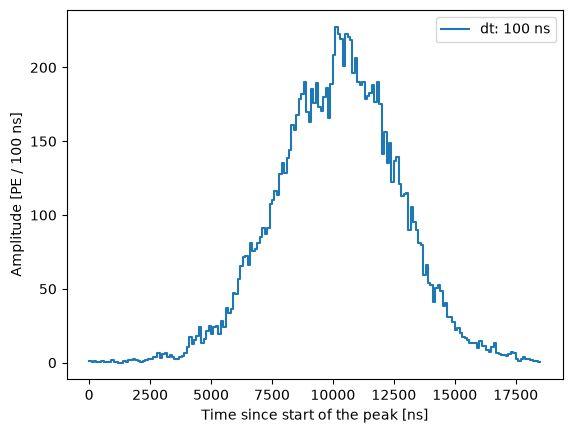

In [62]:
largest_peak = peaks[np.argmax(peaks['area'])]

n_samples = largest_peak['length']
time_axis = np.arange(n_samples) * largest_peak['dt']

plt.step(time_axis, largest_peak['data'][:n_samples], where='post', label=f"dt: {largest_peak['dt']} ns")
plt.xlabel('Time since start of the peak [ns]')
plt.ylabel(f"Amplitude [PE / {largest_peak['dt']} ns]")
plt.legend()
plt.show()

As you can see, the `dt` of this peak is larger than the default of 10 ns. The reason is that the waveform buffer of a peak is only 200 samples long. Signals that are longer than this buffer are automatically downsampled to fit into it. (You can adjust the length of this buffer to your needs.)

## 4.2 Lineage

How does strax know whether stored data matches what you ask for? Every data type has a **lineage**. The lineage contains all the plugins, their versions and their settings that are needed to make your data, all the way down to the raw data (or to whichever data type is your entry point into strax, the one without dependencies). The context computes the lineage from the registered plugins and the current configuration. `st.key_for` returns the key strax uses to look for the data:

In [63]:
key = st.key_for(SHORT_RUN, 'records')
key

012882-records-wqcspukalw

`PulseProcessing`, which provides `records`, is the second plugin in our processing chain, so its lineage contains only two plugins:

In [64]:
key.lineage

{'pulse_counts': ('PulseProcessing',
  '0.1.0',
  {'n_tpc_pmts': 'detector://n_tpc_pmts',
   'baseline_samples': 40,
   'hit_min_amplitude': 15,
   'save_outside_hits': (3, 20)}),
 'raw_records': ('DAQReader', 'MOCKTESTDATA', {})}

The lineage is a dictionary with one entry per plugin in the chain. Each entry contains the plugin name, its version, and the settings it uses. Two details:

* A plugin with several outputs appears only once, under the name of its last output. That's why `PulseProcessing` is listed as `pulse_counts` and not `records`.
* Settings that come from `detector.yaml` appear as their `URLConfig` string, for example `'detector://n_tpc_pmts'`. These strings can be more complex, depending on the type of setting. For example, they could point to a map for position-dependent corrections. In this case, the URL config encodes the path to the file, how to load the file, and how to interpolate it, all through different protocols (we will see more of this in a moment).

The lineage of a higher-level data type contains the lineages of everything below it, so it gets long quickly:

In [65]:
st.key_for(SHORT_RUN, 'peak_basics').lineage

{'peak_basics': ('PeakBasics',
  '0.0.1',
  {'n_top_pmts': 'detector://n_top_pmts'}),
 'peaks': ('Peaks', '0.0.1', {'merge_without_s1': True}),
 'lone_hits': ('Peaklets',
  '0.0.2',
  {'gain_model': 'numpy:///mnt/d/XLZD/mymodules/abstrax/abstrax/resources/fake_to_pe_494_0.005.npy',
   'n_tpc_pmts': 'detector://n_tpc_pmts',
   'n_top_pmts': 'detector://n_top_pmts',
   'hit_min_amplitude': 15,
   'peaklet_gap_threshold': 700,
   'peak_left_extension': 30,
   'peak_right_extension': 200,
   'peak_min_pmts': 2,
   'peaklet_max_duration': 10000000,
   'peak_split_gof_threshold': (None,
    ((0.5, 1.0), (6.0, 0.4)),
    ((2.5, 1.0), (5.625, 0.4))),
   'peak_split_filter_wing_width': 70,
   'peak_split_min_area': 40.0,
   'peak_split_iterations': 20,
   'saturation_correction_on': True,
   'saturation_reference_length': 100,
   'saturation_min_reference_length': 20,
   'tight_coincidence_window_left': 50,
   'tight_coincidence_window_right': 50,
   'store_data_top': True,
   'store_data_start

strax turns this dictionary into the short **lineage hash** that you saw in the folder names in section 2. If anything in the lineage changes, a plugin version or a setting, the hash changes, and strax treats the data as different data.

### Why raw data must keep its lineage

The lineage of our `raw_records` is special: `('DAQReader', 'MOCKTESTDATA', {})`. The raw data interface plugin, which serves as the entry point into strax, has a fixed version and no settings. This is on purpose: strax doesn't *compute* raw data, it only *finds* it on disk and translates it into the strax format, for example from the binary files written by a DAQ system. Usually, these binary files are deleted afterwards, and since any change of the lineage would prevent us from loading the raw data, the lowest plugin in the processing chain has only untracked settings. However, this is just a convention and can be handled differently for your application. Whether a setting is tracked is decided by the user, and we will see more about this in tutorial 3.

`st.show_config` lists all settings that affect a data type, including those of the plugins below it. The columns show the default value, the current value (`<OMITTED>` means the default is used), and which data types the setting applies to:

In [66]:
st.show_config('records')

,option,default,current,applies_to,help
0,n_tpc_pmts,detector://n_tpc_pmts,<OMITTED>,"(records, pulse_counts)",Total number of TPC PMT channels.
1,baseline_samples,40,<OMITTED>,"(records, pulse_counts)",Number of samples at the start of each pulse u...
2,hit_min_amplitude,15,<OMITTED>,"(records, pulse_counts)",Minimum hit amplitude in ADC counts above base...
3,save_outside_hits,"(3, 20)",<OMITTED>,"(records, pulse_counts)","(left, right) samples to preserve on each side..."
4,check_raw_record_overlaps,True,<OMITTED>,"(records, pulse_counts)",Raise if any two pulses in the same channel ov...
5,allow_sloppy_chunking,False,<OMITTED>,"(records, pulse_counts)",Accept incorrectly chunked pulse fragments by ...


Let's change one setting, the threshold of our hit finder `hit_min_amplitude`, and see how the lineage changes:

In [67]:
st.set_config({'hit_min_amplitude': 20})
print(st.is_stored(SHORT_RUN, 'records'), st.key_for(SHORT_RUN, 'records').lineage_hash)
st.set_config({'hit_min_amplitude': 15})
print(st.is_stored(SHORT_RUN, 'records'), st.key_for(SHORT_RUN, 'records').lineage_hash)

False fkpjv3ehsj
True wqcspukalw


If a data type can no longer be found after changing a setting, strax automatically computes it for you, starting from the highest data type that is still available.

In [68]:
st.set_config({'hit_min_amplitude': 20})
st.make(SHORT_RUN, 'records')

Both versions of `records` (and `pulse_counts` that is also provided by the same plugin) are now stored side by side, each in its own folder:

In [69]:
sorted(os.listdir(NEW_OUTPUT_FOLDER))

['012882-lone_hits-ecoajn2gsp',
 '012882-merged_s2s-duzyfy6pmv',
 '012882-peak_basics-t7ibxh2r4t',
 '012882-peaklet_classification-fwlgi2ltri',
 '012882-peaklets-ecoajn2gsp',
 '012882-pulse_counts-fkpjv3ehsj',
 '012882-pulse_counts-wqcspukalw',
 '012882-records-fkpjv3ehsj',
 '012882-records-wqcspukalw']

## 4.3 URL configs

So far, the settings we changed were plain numbers, like `hit_min_amplitude`. Many settings, however, describe the detector or come from files: the number of PMTs, the drift velocity, the PMT gains, correction maps. strax handles these with **URL configs** (`strax.URLConfig`). Instead of the value itself, such a setting holds a string that tells strax *where to get* the value. It is written like a web address:

```
protocol://argument?parameter=value&parameter2=value2
```

* The **protocol** names a function that produces the value, for example the function/protocol `detector`.
* The **argument** is passed to that function/protocol, for example the key `g1`.
* Optional **parameters** appear after the `?` and are passed to the function as keyword arguments. Several parameters are separated by `&`.

When strax sets up a plugin, it evaluates the URL, and the plugin only sees the result. Let's look at the `EnergyEstimates` plugin, whose setting `g1` is a URL config:

In [70]:
plugin = st.get_single_plugin(SHORT_RUN, 'energy_estimates')

print('Setting:', plugin.config['g1'])
print('Value:  ', plugin.g1)

Setting: detector://g1
Value:   0.151


`detector://g1` tells strax to look up `g1` in abstrax's `detector.yaml`. This is a fairly simple protocol, mainly used to provide dummy maps and configs for abstrax. There are also more complex protocols. To get an overview of all currently registered protocols, you can run:

In [71]:
strax.URLConfig.protocol_descr()

,name,description,signature,location
0,detector://,Resolve ``detector://key`` to a value from the...,"(key: 'str', **_) -> 'Any'",abstrax.url_protocols
1,pkg://,Load a packaged resource from ``abstrax/resour...,"(name: 'str', fmt: 'str' = 'auto', **_) -> 'Any'",abstrax.url_protocols
2,yaml://,Load a YAML file by absolute or working-direct...,"(path: 'str', **_) -> 'Any'",abstrax.url_protocols
3,json_file://,Load a JSON file by absolute or working-direct...,"(path: 'str', **_) -> 'Any'",abstrax.url_protocols
4,numpy://,Load a NumPy array (.npy or .npz) by path.,"(path: 'str', **_) -> 'np.ndarray'",abstrax.url_protocols
5,csv://,Load a CSV file by path and return a pandas Da...,"(path: 'str', index_col: 'str' = '0', **_)",abstrax.url_protocols
6,constant://,Identity protocol. Useful when a plugin field ...,"(value: 'Any', **_) -> 'Any'",abstrax.url_protocols
7,dummy_map://,Resolve ``dummy_map://value?shape=[n]`` to a :...,"(value: 'str', shape: 'tuple' = (), **_) -> 'D...",abstrax.url_protocols
8,strax_folder://,Resolve ``strax_folder://dir?run_id=...&data_t...,"(base_dir: 'str', run_id: 'str', data_type: 's...",abstrax.url_protocols


All of them come from abstrax: strax provides the machinery, but no protocols of its own (TODO: This may change). A setting without `://`, or with an unknown protocol, is used as it is. That's why plain values like `hit_min_amplitude = 15` work in the same way.

### Dry evaluation

To check what a URL returns, you don't need a plugin: `strax.URLConfig.evaluate_dry` evaluates it directly. This is the quickest way to test a URL before you use it as a setting:

In [72]:
strax.URLConfig.evaluate_dry('detector://g1')

0.151

In [73]:
strax.URLConfig.evaluate_dry('detector://n_tpc_pmts')

494

### Stacking protocols

URLs can be stacked: the argument of a protocol can itself be a URL. strax evaluates them from the inside out. It evaluates the innermost URL first, and passes its result as the argument to the protocol in front of it.

As an example, `yaml://` loads any YAML file. Let's load the whole detector description:

In [74]:
DETECTOR_FILE = Path('../abstrax/config/detector.yaml').resolve()

detector = strax.URLConfig.evaluate_dry(f'yaml://{DETECTOR_FILE}')
detector

{'n_tpc_pmts': 494,
 'n_top_pmts': 253,
 'n_bottom_pmts': 241,
 'top_pmt_indices': [0, 253],
 'bottom_pmt_indices': [253, 494],
 'pmt_to_pe': 0.005,
 'tpc_length': 148.6515,
 'tpc_radius': 66.4,
 'drift_velocity_liquid': 6.26e-05,
 'electron_lifetime_liquid': 20000000.0,
 'w_value_ev': 13.7,
 'g1': 0.151,
 'g2': 30.0}

To pick a single entry from this dictionary, we need a protocol that takes a dictionary and returns one of its entries. abstrax doesn't have one, so let's write it ourselves. A protocol is just a Python function, registered under a name with `strax.URLConfig.register`. Its first argument is the URL argument, or the result of the inner URL. The URL parameters are passed as keyword arguments:

In [75]:
def get_key(dictionary, key):
    # Return one entry of a dictionary
    return dictionary[key]

# A protocol name can only be registered once, so running this cell a second time raises an error
try:
    strax.URLConfig.register('get_key', get_key)
except ValueError as error:
    print('Error:', error)

Now we can stack the two protocols:

In [76]:
url = f'get_key://yaml://{DETECTOR_FILE}?key=g1'
strax.URLConfig.evaluate_dry(url)

0.151

`strax.URLConfig.url_to_ast` shows how strax reads a URL: as nested `(protocol, argument, parameters)` tuples. The inner tuple loads the file with `yaml`, and its result becomes the argument of `get_key`.

In [77]:
strax.URLConfig.url_to_ast(url)

('get_key',
 ('yaml',
  '/mnt/d/XLZD/mymodules/abstrax/abstrax/config/detector.yaml',
  {'key': 'g1'}),
 {'key': 'g1'})

The parameters at the end of the URL (`?key=g1`) are offered to every protocol in the stack, and each protocol takes only the parameters its function accepts.

Real detectors use this a lot. In straxen, for example, the URL of a correction map typically stacks one protocol that fetches the right file, one that reads it, and one that turns its content into an interpolating map.

### Settings that depend on the run

At this point, you may wonder why URL configs were introduced in the first place. Some settings are time-dependent and differ from run to run. An example is the electron lifetime, which changes with the purity of the xenon. For such settings, a URL can use attributes of the plugin that evaluates it: a parameter value written as `plugin.<attribute>` is replaced by that attribute of the plugin. The most common one is `plugin.run_id`, the run the plugin is processing.

As an example, let's write a small file with one electron lifetime per run into our output folder. In a real experiment, such values come from a calibration, and they can be stored anywhere a protocol can read them from. The second run, `000001`, is made up for this example:

In [78]:
LIFETIME_FILE = os.path.join(OUTPUT_FOLDER, 'electron_lifetime_per_run.json')

electron_lifetimes = {   # in ns
    SHORT_RUN: 1.5e7,
    '000001': 1.2e7,
}
with open(LIFETIME_FILE, 'w') as f:
    json.dump(electron_lifetimes, f)

We read the file with `json_file://`, and pick the entry of the run with our `get_key` protocol. The key is not fixed, but `plugin.run_id`:

In [79]:
url = f'get_key://json_file://{LIFETIME_FILE}?key=plugin.run_id'

try:
    strax.URLConfig.evaluate_dry(url)
except ValueError as error:
    print('Error:', error)

Error: The URL parameter key depends on the plugin. You must specify the value for this parameter for this URL to be evaluated correctly. Try passing key as a keyword argument. e.g.: `URLConfig.evaluate_dry(get_key://json_file:///mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data/electron_lifetime_per_run.json?key=plugin.run_id, key=SOME_VALUE)`.


A dry evaluation has no plugin, so strax doesn't know which run is meant, and asks us to give the value of the parameter `key` ourselves:

In [80]:
print('SHORT_RUN:', strax.URLConfig.evaluate_dry(url, key=SHORT_RUN))
print('000001:   ', strax.URLConfig.evaluate_dry(url, key='000001'))

SHORT_RUN: 15000000.0
000001:    12000000.0


Inside a plugin, strax fills in the run automatically. Let's use the URL for the `electron_lifetime_liquid` setting of the `CorrectedAreas` plugin, in a copy of our context. The same setting now gives a different value for each run:

In [81]:
st_lifetime = st.new_context()
st_lifetime.set_config({'electron_lifetime_liquid': url})

print('Default setting:', st.get_single_plugin(SHORT_RUN, 'corrected_areas').config['electron_lifetime_liquid'])
print('SHORT_RUN:', st_lifetime.get_single_plugin(SHORT_RUN, 'corrected_areas').electron_lifetime_liquid)
print('000001:   ', st_lifetime.get_single_plugin('000001', 'corrected_areas').electron_lifetime_liquid)

Default setting: detector://electron_lifetime_liquid
SHORT_RUN: 15000000.0
000001:    12000000.0


### URL configs and the lineage

So how does this affect the lineage of our data? The lineage stores the URL string, not the value itself:

In [82]:
st.key_for(SHORT_RUN, 'energy_estimates').lineage['energy_estimates']

('EnergyEstimates',
 '0.0.2',
 {'g1': 'detector://g1',
  'g2': 'detector://g2',
  'w_value_ev': 'detector://w_value_ev'})

This has two important consequences.

**1. Different URLs give different hashes, even if they return the same value.** Let's set `g1` to our stacked URL in a copy of the context. It returns the same value as `detector://g1`, but the key changes:

In [83]:
st_url = st.new_context()
st_url.set_config({'g1': f'get_key://yaml://{DETECTOR_FILE}?key=g1'})

print('g1 in st:    ', st.get_single_plugin(SHORT_RUN, 'energy_estimates').g1)
print('g1 in st_url:', st_url.get_single_plugin(SHORT_RUN, 'energy_estimates').g1)
print('Key in st:    ', st.key_for(SHORT_RUN, 'energy_estimates'))
print('Key in st_url:', st_url.key_for(SHORT_RUN, 'energy_estimates'))

g1 in st:     0.151
g1 in st_url: 0.151
Key in st:     012882-energy_estimates-sw77y4qauo
Key in st_url: 012882-energy_estimates-hall26rguj


**2. If the content behind a URL changes, the hash does not.** If you edit a value in `detector.yaml`, `detector://g1` stays the same string, and so does the lineage hash. strax would then happily load data that was made with the old value.

### So why is this behavior desired?

This logic allows us to avoid run-dependent lineages. Imagine that the lineage encoded the value of the electron lifetime instead of its URL. Then each run would have its own hash, and the entire logic behind lineages and hashes would break.

Instead, it is advisable to work with versioned, time-dependent corrections, stored for example as files in a local directory or in a database. Whenever you update corrections for timestamps in the past, you increment the version of your corrections, and thereby change the URL config and the hash.

## 4.4 "Why can't strax find my data?"

Especially in the beginning, this is one of the most common questions when working with strax. Usually, the answer is that the lineage of the stored data differs from the lineage of your context, for example because of a different plugin version or a different setting. `st.compare_metadata` shows the difference. Here we compare what our current context expects with the `peak_basics` we made in section 4.1:

In [84]:
# First, let's get the absolute path to a metadata file:
peak_basics_dir = [directory for directory in os.listdir(NEW_OUTPUT_FOLDER) if 'peak_basics' in directory][0]
meta_data_file = [file for file in os.listdir(os.path.join(NEW_OUTPUT_FOLDER, peak_basics_dir)) if 'metadata' in file][0]
absolute_path_to_metadata_file_to_check  = os.path.join(NEW_OUTPUT_FOLDER, peak_basics_dir, meta_data_file)
print(absolute_path_to_metadata_file_to_check)

# Now compare the file with the current context:
st.compare_metadata((SHORT_RUN, 'peak_basics'), absolute_path_to_metadata_file_to_check)

/mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data_new/012882-peak_basics-t7ibxh2r4t/peak_basics-t7ibxh2r4t-metadata.json
Both metadata are not available together. Comparing lineages!

> values_changed
	 in ['lone_hits'][2]['hit_min_amplitude']
		20 -> 15
	 in ['pulse_counts'][2]['hit_min_amplitude']
		20 -> 15


The output lists every entry of the metadata that differs. In our case, it shows that our context is configured with a `hit_min_amplitude` of 20, while the stored data was made with 15.

# 5. Runs without a database

Large experiments usually keep a **run database** that stores metadata about every run, for example when it started and ended, the run mode (for example a calibration with a certain source), tags and comments. strax doesn't need such a database to load and process data. However, run metadata is convenient for keeping track of your data, and strax can store run metadata files in a local `DataDirectory` (you can also use a database, but then you may need to write your own storage frontend and backend). The run metadata files are named `<run_id>-metadata.json`.

## 5.1 Reading run metadata

`st.run_metadata` returns the run metadata of a run. Our test runs don't have any yet, so strax raises an error:

In [85]:
try:
    st.run_metadata(SHORT_RUN)
except strax.RunMetadataNotAvailable as error:
    print('Error:', error)

Error: No file at /mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data_new/012882-metadata.json, cannot find run metadata for 012882


## 5.2 Writing run metadata

Run metadata is a plain dictionary. strax uses the following fields:

| Field | Meaning |
|---|---|
| `name` | The run ID |
| `start`, `end` | Start and end of the run, as `datetime` objects |
| `mode` | The run mode, for example the calibration source |
| `tags` | A list of tags, each a dictionary with a `name` |
| `comments` | A list of comments, each a dictionary with a `comment` |

`start` and `end` must cover all the data of the run, because strax uses them, for example, for `seconds_range`. We take them from the metadata of `raw_records`, rounded down and up to full seconds:

In [86]:
import datetime

raw_metadata = st.get_metadata(SHORT_RUN, 'raw_records')
start_seconds = int(raw_metadata['start'] / 1e9)    # rounded down
end_seconds = int(raw_metadata['end'] / 1e9) + 1    # rounded up

run_start = datetime.datetime.fromtimestamp(start_seconds, tz=datetime.timezone.utc)
run_end = datetime.datetime.fromtimestamp(end_seconds, tz=datetime.timezone.utc)
print('Run start:', run_start)
print('Run end:  ', run_end)

Run start: 1970-01-01 00:00:00+00:00
Run end:   1970-01-01 00:00:05+00:00


Now we fill in the run metadata, and write it with our writable storage frontend. Let's add a new directory for this purpose, to keep data and run metadata separated. As an example, we write the metadata of two different runs:

In [87]:
run_metadata_short_run = {
    'name': SHORT_RUN,
    'start': run_start,
    'end': run_end,
    'mode': 'dummy_sim',
    'tags': [{'name': 'simulation'}, {'name': 'short_run'}],
    'comments': [{'comment': 'Short simulated dummy run, with raw_records'}],
}

ANOTHER_RUNID = '004242'
second_run_start = run_start - datetime.timedelta(hours=1)
second_run_end = second_run_start + datetime.timedelta(minutes=10)
run_metadata_another_run = {
    'name': ANOTHER_RUNID,
    'start': second_run_start,
    'end': second_run_end,
    'mode': 'another_run_mode',
    'tags': [{'name': 'some_other_tag'}, ],
    'comments': [{'comment': 'Some other run'}],
}

RUN_METADATA_FOLDER = Path('./run_metadata').resolve()
# Read only ensure that no data is written into the metadata folder:
st.storage.insert(
    0, 
    strax.DataDirectory(path=RUN_METADATA_FOLDER, provide_run_metadata=True, readonly=True) 
)

# Get the storage frontend:
sf = st.storage[0]

# Write the run metadata files:
sf.write_run_metadata(SHORT_RUN, run_metadata_short_run)
sf.write_run_metadata(ANOTHER_RUNID, run_metadata_another_run)

The run metadata is now stored as files in `RUN_METADATA_FOLDER`, and strax can read them:

In [88]:
st.run_metadata(SHORT_RUN)

{'comments': [{'comment': 'Short simulated dummy run, with raw_records'}],
 'end': datetime.datetime(1970, 1, 1, 0, 0, 5),
 'mode': 'dummy_sim',
 'name': '012882',
 'start': datetime.datetime(1970, 1, 1, 0, 0),
 'tags': [{'name': 'simulation'}, {'name': 'short_run'}]}

In [89]:
st.run_metadata(ANOTHER_RUNID)

{'comments': [{'comment': 'Some other run'}],
 'end': datetime.datetime(1969, 12, 31, 23, 10),
 'mode': 'another_run_mode',
 'name': '004242',
 'start': datetime.datetime(1969, 12, 31, 23, 0),
 'tags': [{'name': 'some_other_tag'}]}

Please note that these run metadata files are not versioned. If you write the metadata of the same run twice into the same folder, the file is overwritten. If several folders contain metadata for the same run, strax reads it from the first storage frontend in its search order.

With run metadata in place, we can now conveniently search for runs, for example by their tags, with `st.select_runs`:

In [90]:
st.select_runs()

,name,mode,tags,number,source
0,004242,another_run_mode,some_other_tag,4242,
1,012882,dummy_sim,"simulation,short_run",12882,


You can select runs by run mode and by tags. Both accept wildcards (`*`):

In [91]:
st.select_runs(run_mode='dummy*', include_tags='simulation')

,name,mode,tags,number,source
1,012882,dummy_sim,"simulation,short_run",12882,


With `available`, `select_runs` only returns runs for which all listed data types are stored, and adds a column for each of them:

In [92]:
# Change the config back:
st.set_config({'hit_min_amplitude': 15})
st.select_runs(available=('peak_basics'))

Checking data availability:   0%|          | 0/1 [00:00<?, ?it/s]

,name,mode,tags,number,source,peak_basics_available
1,012882,dummy_sim,"simulation,short_run",12882,,True


This is how you start an analysis: select the runs you need, check which data is available for them, and then load it.

# 7. Summary

Congratulations, you made it through the first tutorial! Here is what you have learned.

**strax and abstrax**
* strax is the experiment-neutral engine: plugins, the context, storage, chunked processing, lineage and URL configs. abstrax adds a set of plugins for a generic dual-phase TPC, with the detector described in `detector.yaml`.
* You always work through a **context**. It knows the registered plugins, their configuration and where data is stored.

**How strax organises data**
* Data is a stream of **time intervals**, sorted by time, with integer times in ns since the unix epoch. Events are not the unit the data is organised in, but just another data type.
* A **plugin** turns data types into new data types. Data types that describe the same objects row by row form a **data kind**.
* A **run** is cut into **chunks** that cover it without gaps. On disk, each data type of a run is a folder `<run_id>-<data_type>-<lineage_hash>`, with one file per chunk and a `metadata.json`.

**Loading data**
* `get_array` returns structured arrays, `get_df` returns DataFrames. Use structured arrays for data with waveforms or per-channel information.
* Check the size of a data type first, and load only what you need: select rows, a time range, or columns. For very large data, loop over the chunks.

**Processing and lineage**
* strax makes missing data on demand, starting from the highest data type that is stored. Whether a data type is saved depends on the plugin's `save_when`.
* The **lineage** contains all plugins, their versions and their settings, down to the raw data. Changing a setting changes the lineage hash of every data type that depends on it, and only those are reprocessed. It is recommended to never change the lineage of the lowest data type.
* **URL configs** (`protocol://argument?parameter=value`) load settings from files or other resources. You can test them with a dry evaluation, stack them, and make them depend on the run with `plugin.run_id`. The lineage stores the URL, not its value.
* If strax can't find your data, compare the lineage of the stored data with what your context expects.

**Runs**
* strax doesn't need a run database, but it provides simple means to organize your data. Run metadata can be stored as a file next to the data on disk, and `select_runs` gives you an overview of all runs. This lets you search for data without having to maintain a fully-fledged run database.

## The most important functions

| Function | What it does | Section |
|---|---|---|
| **Context and storage** | | |
| `abstrax.print_versions()` | Prints the versions of strax, abstrax and Python | 2.1 |
| `abstrax.contexts.abstrax_context(output_folder=...)` | Creates a context with all abstrax plugins | 2.2 |
| `st.storage` | Lists the storage frontends of the context | 2.3 |
| `st.storage.append(strax.DataDirectory(path, readonly=True))` | Adds a directory with data, read-only | 2.3 |
| `st.writable_storage()` | Lists the storage frontends new data is saved to | 2.3 |
| `st.is_stored(run_id, data_type)` | Checks whether a data type of a run is stored | 2.3, 4.1 |
| `st.get_metadata(run_id, data_type)` | Returns the metadata of stored data, including its chunks | 2.3 |
| **Exploring plugins and data types** | | |
| `st.tree`, `st.get_dependencies(data_type)` | Shows which data types a data type depends on | 1.4 |
| `st.get_data_kinds()` | Groups the data types by data kind | 1.4 |
| `st.get_single_plugin(run_id, data_type)` | Returns the plugin that makes a data type | 1.4, 4.3 |
| `st.data_info(data_type)` | Lists the fields of a data type, with descriptions | 3.1 |
| `st.search_field(field)` | Finds the data types that contain a field | 3.1 |
| **Loading data** | | |
| `st.get_array(run_id, data_types)` | Loads data as a numpy structured array | 3.1, 3.2 |
| `st.get_df(run_id, data_types)` | Loads data as a pandas DataFrame | 3.1 |
| `st.size_mb(run_id, data_type)` | Returns the size of a data type in memory | 3.3 |
| `selection=`, `seconds_range=`, `time_range=`, `keep_columns=`, `drop_columns=` | Arguments of `get_array` and `get_df` to load only part of the data | 3.3 |
| `st.get_iter(run_id, data_type)` | Loops over the data chunk by chunk | 3.4 |
| **Processing and lineage** | | |
| `st.make(run_id, data_type, save=...)` | Makes and saves data, without loading it | 4.1 |
| `st.key_for(run_id, data_type)` | Returns the key of a data type, with its `lineage` and lineage hash | 2.3, 4.2 |
| `st.show_config(data_type)` | Lists all settings that affect a data type | 4.2 |
| `st.set_config({...})` | Changes settings of the context | 4.2 |
| `st.new_context()` | Makes a copy of the context, for example to test other settings | 4.3 |
| `st.compare_metadata((run_id, data_type), metadata_file)` | Shows how stored data differs from what the context expects | 4.4 |
| **URL configs** | | |
| `strax.URLConfig.protocol_descr()` | Lists all registered protocols | 4.3 |
| `strax.URLConfig.evaluate_dry(url, ...)` | Evaluates a URL without a plugin | 4.3 |
| `strax.URLConfig.url_to_ast(url)` | Shows how a (stacked) URL is read | 4.3 |
| `strax.URLConfig.register(name, function)` | Registers a new protocol | 4.3 |
| **Runs** | | |
| `st.run_metadata(run_id)` | Returns the run metadata of a run | 5.1 |
| `write_run_metadata(run_id, metadata)` | Writes run metadata, called on a writable storage frontend | 5.2 |
| `st.select_runs(run_mode=..., include_tags=..., available=...)` | Lists and selects runs | 5.2 |

## What's next?

* **Tutorial 2** explains the detector physics behind the data, and what each data level means.
* **Tutorial 3** shows how to write your own plugins.
* **Tutorial 4** covers data quality cuts and their acceptances.